# 03 · Гибриды без LLM: шаблоны, аналоги из каталога, похожие товары, верификатор

Продолжение [`02_baseline`](02_baseline.ipynb). Каждая ступень закрывает ошибку, найденную при разборе ошибок baseline:

| Ступень | Модуль | Какую ошибку baseline закрывает |
|---|---|---|
| Выученные шаблоны | `attrx/patterns.py` | 68% пропусков, которые подтверждаются текстом, — составные числа «8/128Gb», «42.5x72.2x6.3 см», «1366x768». Какая позиция кортежа — какая характеристика, выучено на train отдельно для каждой категории |
| Аналоги из каталога | `attrx/analogs.py` | 84% эталона нет в тексте. Тот же товар у другого продавца (train-часть каталога, в том числе товары без описания) даёт паспортные поля. Значение предлагается, только если аналоги согласны |
| Похожие товары | `attrx/analogs.py`, `SimilarItems` | У 55% карточек точного аналога (общий код модели) нет. Товары той же линейки бренда (близкое название без кода) часто совпадают паспортом: страна, гарантия, комплектация. Значение берётся, только если ≥ 3 похожих товара единодушны (согласие ≥ 0.8) |
| Верификатор (аналог JEV) | `attrx/verifier.py` | Уверенность не откалибрована: ECE 0.21, precision@accept 0.67. Градиентный бустинг + изотоническая калибровка на val (GroupKFold по продавцу) |

**Политика статусов** (`attrx.train.assign_status`):
- `accept` — значение публикуется сразу. Нужна вероятность не ниже порога, выбранного на val (точность ≥ 0.95), **и** подтверждение в тексте карточки;
- `review` — значение уходит модератору. Нужна вероятность ≥ 0.5. Сюда же попадают значения только от аналога или похожих товаров, если у них нет подтверждения в тексте;
- `reject` — значение не показываем.

Все конфигурации считаются на одной выборке `test_core` одной функцией оценки. Обучение и пороги — только на train/val.

In [1]:
import json, os, time
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

from attrx.catalog import DataPaths, build, load
from attrx import metrics as M
from attrx.train import fit_components, fit_verifier, assign_status, status_summary, save, load_artifact
from attrx.cli_real import CONFIGS as STACKS

candidates = [os.environ.get("ATTRX_DATA_DIR"), "../data/real", str(Path.home() / "hackathon_data")]
DATA_DIR = next(Path(p) for p in candidates if p and (Path(p) / "cu_ws").exists())
P = DataPaths(DATA_DIR)
REPORTS, FIG = Path("../reports"), Path("../reports/figures")
pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(50); pl.Config.set_tbl_width_chars(180); pl.Config.set_tbl_cols(16)
if not (P.work / "analog_facts.parquet").exists():
    print(build(P))
cards, gold, schema, cats = (load(P, n) for n in ("cards", "gold", "schema", "categories"))
core = M.eval_sample(cards, cats, "test")
sup = M.supported_flags(core, gold, schema)
print(f"test_core: {core.height} карточек, {core['category_id'].n_unique()} категорий")

test_core: 1398 карточек, 30 категорий


## 1. Обучение компонентов (train)

In [2]:
comp = load_artifact(P, "components")
if comp is None or getattr(comp, "similar", None) is None:
    comp = fit_components(P)
    save(comp, P, "components")
print("время обучения, с:", comp.timings)
print("шаблоны:", comp.patterns.stats, "| аналоги:", comp.analogs.stats)
print("похожие товары: категорий", len(comp.similar.word_postings), "| k =", comp.similar.k, "| min_sim =", comp.similar.min_sim,
      "| min_agreement =", comp.similar.min_agreement)
examples = [("761", "Смартфоны"), ("36480", "Матрасы"), ("1682", "Телевизоры")]
for cat, name in examples:
    for key, rules in comp.patterns.rules.get(cat, {}).items():
        print(f"{name:10} кортеж {key}: " + "; ".join(f"{'целиком' if pos == -1 else 'поз.' + str(pos)} -> {t.attribute} ({p:.2f})" for pos, t, p in rules[:4]))

время обучения, с: {'lexicon_s': 9.9, 'patterns_s': 35.7, 'analogs_s': 12.2}
шаблоны: {'categories': 329, 'rules': 1067} | аналоги: {'offers': 379875, 'categories': 1077, 'facts': 9878133}
похожие товары: категорий 1093 | k = 10 | min_sim = 0.3 | min_agreement = 0.8
Смартфоны  кортеж ('x', 2): поз.0 -> Разрешение по вертикали (0.85); поз.1 -> Разрешение пo горизонтали (0.85)
Смартфоны  кортеж ('/', 2): поз.0 -> Оперативная память (RAM) (0.98); поз.1 -> Встроенная память (ROM) (0.98); целиком -> Оперативная и встроенная память (0.97)
Смартфоны  кортеж ('x', 3): поз.0 -> Высота (0.94); поз.1 -> Ширина (0.91); поз.2 -> Толщина (0.91); целиком -> Габаритные размеры (В*Ш*Т) (0.88)
Матрасы    кортеж ('x', 2): поз.0 -> Ширина (1.00); поз.1 -> Длина (1.00)
Телевизоры кортеж ('x', 2): поз.0 -> Разрешение пo горизонтали (0.79); поз.1 -> Разрешение по вертикали (0.79)
Телевизоры кортеж ('x', 3): поз.1 -> Ширина (0.74); поз.1 -> Ширина без подставки (0.70)


## 2. Верификаторы и пороги (val)

Для каждой конфигурации обучается свой верификатор: от набора источников зависят признаки кандидатов. Порог `accept` — минимальная вероятность, при которой точность на OOF-предсказаниях val не ниже 0.95.

In [3]:
verifiers = load_artifact(P, "verifiers") or {}
for name, kw in ((n, k) for n, k in STACKS.items() if "judge" not in k):  # судья — в 05_judge
    if name not in verifiers:
        t = time.time()
        verifiers[name] = fit_verifier(comp.stack(**kw), P)
        print(name, f"{time.time() - t:.0f} c")
    ver, thr = verifiers[name]
    print(f"{name:26} {ver.report} | порог accept = {thr:.3f}")
save(verifiers, P, "verifiers")

patterns                   {'n': 43799, 'positive_rate': 0.6695, 'oof_auc': 0.8218, 'oof_auc_raw_confidence': 0.6346} | порог accept = 0.952
patterns+analogs           {'n': 86669, 'positive_rate': 0.7372, 'oof_auc': 0.7991, 'oof_auc_raw_confidence': 0.5712} | порог accept = 0.881
patterns+analogs+similar   {'n': 108180, 'positive_rate': 0.7366, 'oof_auc': 0.7964, 'oof_auc_raw_confidence': 0.5585} | порог accept = 0.891


WindowsPath('C:/Users/ibrag/hackathon_data/work/artifacts/verifiers.pkl')

## 3. Сравнение конфигураций на `test_core`

Для конфигураций без верификатора действует прежняя политика baseline: `accept` при уверенности ≥ 0.8, `review` при ≥ 0.5. Precision, recall и F1 считаются по показанным значениям (`accept` + `review`).

In [4]:
CONFIGS = {
    "1 baseline (словари)":              dict(stack=comp.stack(patterns=False, analogs=False), accept=0.8),
    "2 + шаблоны":                        dict(stack=comp.stack(analogs=False), accept=0.8),
    "3 + шаблоны + верификатор":          dict(stack=comp.stack(analogs=False, verifier=verifiers["patterns"][0]), accept=verifiers["patterns"][1]),
    "4 + шаблоны + аналоги":              dict(stack=comp.stack(similar=False), accept=0.8),
    "5 + шаблоны + аналоги + верификатор": dict(stack=comp.stack(similar=False, verifier=verifiers["patterns+analogs"][0]), accept=verifiers["patterns+analogs"][1]),
    "6 + похожие товары + верификатор":   dict(stack=comp.stack(verifier=verifiers["patterns+analogs+similar"][0]), accept=verifiers["patterns+analogs+similar"][1]),
}

def evaluate(name, cfg, text_required=True, ci=True):
    t = time.time(); frame = cfg["stack"].predict_frame(core); ms = 1000 * (time.time() - t) / core.height
    frame = assign_status(frame, cfg["accept"], review=0.5, text_required=text_required)
    shown = frame.filter(pl.col("status") != "reject")
    pairs = M.score_pairs(shown, gold, core, schema, sup)
    s = M.summarize(pairs).row(0, named=True)
    st = {r["status"]: r for r in status_summary(pairs).iter_rows(named=True)}
    acc, rev = st.get("accept", {}), st.get("review", {})
    row = {"config": name, "precision": s["precision"], "recall": s["recall"], "f1": s["f1"],
           "traffic_weighted_f1": M.traffic_weighted_f1(pairs, cats), "recall_supported": s["recall_supported"],
           "auto_fill": acc.get("share_of_gold", 0.0), "precision_accept": acc.get("precision"),
           "review_share": rev.get("share_of_gold", 0.0), "review_precision": rev.get("precision"),
           "ece": M.calibration(M.score_pairs(frame, gold, core, schema))[0], "ms_per_card": ms, "llm_share": 0.0}
    if ci:
        lo, hi = M.bootstrap_ci(pairs, lambda p: M.traffic_weighted_f1(p, cats), n=100)
        row["twf1_ci"] = f"[{lo:.3f}; {hi:.3f}]"
    return row, frame, pairs

rows, frames, all_pairs = [], {}, {}
for name, cfg in CONFIGS.items():
    row, frames[name], all_pairs[name] = evaluate(name, cfg)
    rows.append(row)
row, _, _ = evaluate("6b то же, аналоги публикуются без проверки", CONFIGS["6 + похожие товары + верификатор"], text_required=False, ci=False)
rows.append(row)
bench = pl.DataFrame(rows)
bench.select("config", "precision", "recall", "f1", "traffic_weighted_f1", "twf1_ci", "auto_fill", "precision_accept",
             "review_share", "review_precision", "ece", "ms_per_card")

config,precision,recall,f1,traffic_weighted_f1,twf1_ci,auto_fill,precision_accept,review_share,review_precision,ece,ms_per_card
str,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64
"""1 baseline (словари)""",0.67942,0.085214,0.151434,0.151925,"""[0.147; 0.158]""",0.048027,0.671305,0.077394,0.684456,0.202383,7.680025
"""2 + шаблоны""",0.691133,0.096161,0.168832,0.171294,"""[0.166; 0.178]""",0.054483,0.694799,0.084652,0.688773,0.180818,9.072884
"""3 + шаблоны + верификатор""",0.80906,0.093341,0.167372,0.169175,"""[0.164; 0.177]""",0.025758,0.983394,0.089611,0.75895,0.060059,9.360931
"""4 + шаблоны + аналоги""",0.809144,0.327153,0.465924,0.47851,"""[0.462; 0.502]""",0.06912,0.799265,0.3352,0.811182,0.17246,18.113991
"""5 + шаблоны + аналоги + верификатор""",0.838921,0.386649,0.529334,0.540005,"""[0.526; 0.558]""",0.05435,0.969749,0.406539,0.821431,0.0163,19.090327
"""6 + похожие товары + верификатор""",0.830388,0.484267,0.611765,0.629709,"""[0.620; 0.642]""",0.049511,0.973812,0.533671,0.817082,0.010249,30.173881
"""6b то же, аналоги публикуются без проверки""",0.830388,0.484267,0.611765,0.629709,null,0.197428,0.943805,0.385754,0.772341,0.010249,31.355294


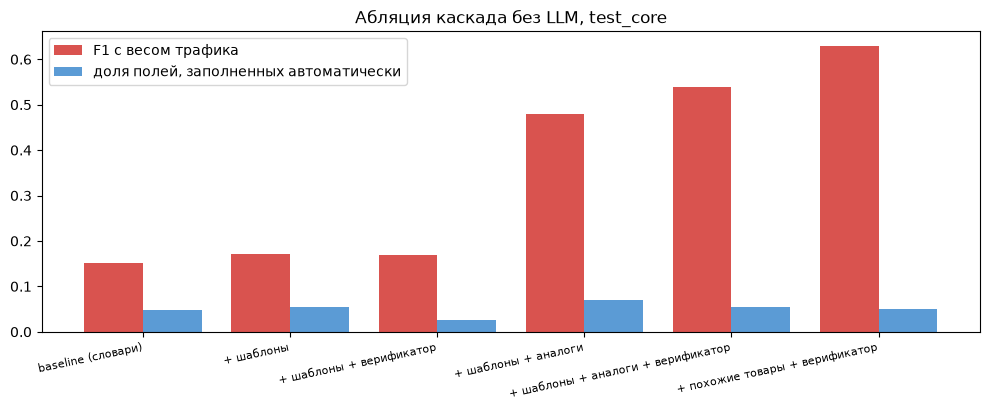

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
labels = [r.split(" ", 1)[1] for r in bench["config"].to_list()[:6]]
x = range(len(labels))
ax.bar([i - 0.2 for i in x], bench["traffic_weighted_f1"][:6], width=0.4, label="F1 с весом трафика", color="#d9534f")
ax.bar([i + 0.2 for i in x], bench["auto_fill"][:6], width=0.4, label="доля полей, заполненных автоматически", color="#5b9bd5")
ax.set_xticks(list(x)); ax.set_xticklabels(labels, rotation=12, ha="right", fontsize=8); ax.legend(); ax.set_title("Абляция каскада без LLM, test_core")
plt.tight_layout(); plt.savefig(FIG / "ablation_no_llm.png"); plt.show()

## 4. Срезы лучшей конфигурации

In [6]:
best = "6 + похожие товары + верификатор"
bp = all_pairs[best]
print(status_summary(bp))
M.summarize(bp, "kind").select("kind", "n_gold", "precision", "recall", "f1", "coverage")

shape: (3, 4)
┌────────┬───────┬───────────┬───────────────┐
│ status ┆ pairs ┆ precision ┆ share_of_gold │
│ ---    ┆ ---   ┆ ---       ┆ ---           │
│ str    ┆ u32   ┆ f64       ┆ f64           │
╞════════╪═══════╪═══════════╪═══════════════╡
│ accept ┆ 3704  ┆ 0.973812  ┆ 0.049511      │
│ empty  ┆ 31183 ┆ 0.0       ┆ 0.416818      │
│ review ┆ 39925 ┆ 0.817082  ┆ 0.533671      │
└────────┴───────┴───────────┴───────────────┘


kind,n_gold,precision,recall,f1,coverage
str,u32,f64,f64,f64,f64
"""bool""",31004,0.868408,0.552348,0.675223,0.636047
"""enum""",18526,0.804515,0.463619,0.588247,0.576271
"""num""",16534,0.802045,0.450647,0.57706,0.561873
"""text""",8748,0.777073,0.350251,0.482862,0.450732


In [7]:
(M.summarize(bp.filter(pl.col("pred").is_not_null()), "source").select("source", "n_pred", "precision")
 .filter(pl.col("n_pred") >= 30))

source,n_pred,precision
str,u32,f64
"""analog""",26992,0.829876
"""similar""",8278,0.825199
"""lexicon""",1394,0.57604
"""number""",1188,0.741582
"""analog+lexicon""",1010,0.869307
"""pattern""",675,0.724444
"""analog+flag""",671,0.989568
"""flag""",643,0.897356
"""analog+brand""",626,0.990415


In [8]:
names = cats.select(pl.col("id").alias("category_id"), "name", "traffic_share")
(M.summarize(bp, "category_id").join(names, on="category_id").sort("traffic_share", descending=True)
 .select("name", "traffic_share", "n_gold", "precision", "recall", "f1").head(15))

name,traffic_share,n_gold,precision,recall,f1
str,f64,u32,f64,f64,f64
"""Смартфоны""",0.077452,5486,0.886061,0.691761,0.776947
"""Стиральные машины""",0.051761,5426,0.822551,0.583487,0.682695
"""Холодильники""",0.051405,3800,0.80745,0.405,0.539432
"""iPhone""",0.041058,3189,0.890983,0.756036,0.817981
"""Телевизоры""",0.040522,6423,0.866293,0.576989,0.692646
"""Ноутбуки""",0.030365,2639,0.886957,0.541114,0.672158
"""Наушники""",0.029517,1752,0.810989,0.421233,0.55447
"""Пылесосы вертикальные""",0.023247,3412,0.796199,0.44197,0.568413
"""Аэрогрили""",0.021868,5259,0.784987,0.27838,0.411005


In [9]:
M.summarize(bp, "seller_type").select("seller_type", "n_gold", "precision", "recall", "f1")

seller_type,n_gold,precision,recall,f1
str,u32,f64,f64,f64
"""1P""",39954,0.816058,0.447715,0.578207
"""3P""",34858,0.844857,0.526163,0.64847


### Гейт «регрессия на срезах»: конфигурация 6 против 5

По контракту новая конфигурация не должна ухудшать F1 больше чем на 0.02 ни на одном срезе из топ-10 категорий по трафику. Дополнительно смотрим 1P/3P и типы характеристик.

In [10]:
prev = all_pairs["5 + шаблоны + аналоги + верификатор"]
def f1_by(pairs, by):
    return M.summarize(pairs, by).select(by, "n_gold", "f1")
top10 = names.sort("traffic_share", descending=True).head(10)
cat_gate = (f1_by(prev, "category_id").rename({"f1": "f1_5"}).join(f1_by(bp, "category_id").select("category_id", pl.col("f1").alias("f1_6")), on="category_id")
            .join(top10, on="category_id").with_columns((pl.col("f1_6") - pl.col("f1_5")).alias("delta")).sort("traffic_share", descending=True))
other = pl.concat([
    f1_by(prev, by).rename({"f1": "f1_5", by: "slice"}).join(f1_by(bp, by).select(pl.col(by).alias("slice"), pl.col("f1").alias("f1_6")), on="slice")
    for by in ("seller_type", "kind")]).with_columns((pl.col("f1_6") - pl.col("f1_5")).alias("delta"))
worst = min(cat_gate["delta"].min(), other["delta"].min())
print(f"худшее изменение F1 на срезах: {worst:+.3f} -> гейт {'пройден' if worst >= -0.02 else 'НЕ пройден'}")
print(other)
cat_gate.select("name", "traffic_share", "n_gold", "f1_5", "f1_6", "delta")

худшее изменение F1 на срезах: +0.003 -> гейт пройден
shape: (6, 5)
┌───────┬────────┬──────────┬──────────┬──────────┐
│ slice ┆ n_gold ┆ f1_5     ┆ f1_6     ┆ delta    │
│ ---   ┆ ---    ┆ ---      ┆ ---      ┆ ---      │
│ str   ┆ u32    ┆ f64      ┆ f64      ┆ f64      │
╞═══════╪════════╪══════════╪══════════╪══════════╡
│ 1P    ┆ 39954  ┆ 0.46955  ┆ 0.578207 ┆ 0.108658 │
│ 3P    ┆ 34858  ┆ 0.592595 ┆ 0.64847  ┆ 0.055875 │
│ bool  ┆ 31004  ┆ 0.554451 ┆ 0.675223 ┆ 0.120772 │
│ enum  ┆ 18526  ┆ 0.498881 ┆ 0.588247 ┆ 0.089366 │
│ num   ┆ 16534  ┆ 0.551826 ┆ 0.57706  ┆ 0.025234 │
│ text  ┆ 8748   ┆ 0.457825 ┆ 0.482862 ┆ 0.025036 │
└───────┴────────┴──────────┴──────────┴──────────┘


name,traffic_share,n_gold,f1_5,f1_6,delta
str,f64,u32,f64,f64,f64
"""Смартфоны""",0.077452,5486,0.770142,0.776947,0.006805
"""Стиральные машины""",0.051761,5426,0.60902,0.682695,0.073675
"""Холодильники""",0.051405,3800,0.471705,0.539432,0.067727
"""iPhone""",0.041058,3189,0.814953,0.817981,0.003028
"""Телевизоры""",0.040522,6423,0.565582,0.692646,0.127063
"""Ноутбуки""",0.030365,2639,0.646377,0.672158,0.025781
"""Наушники""",0.029517,1752,0.291897,0.55447,0.262573
"""Пылесосы вертикальные""",0.023247,3412,0.416193,0.568413,0.152221
"""Аэрогрили""",0.021868,5259,0.273464,0.411005,0.137541


## 5. Калибровка верификатора

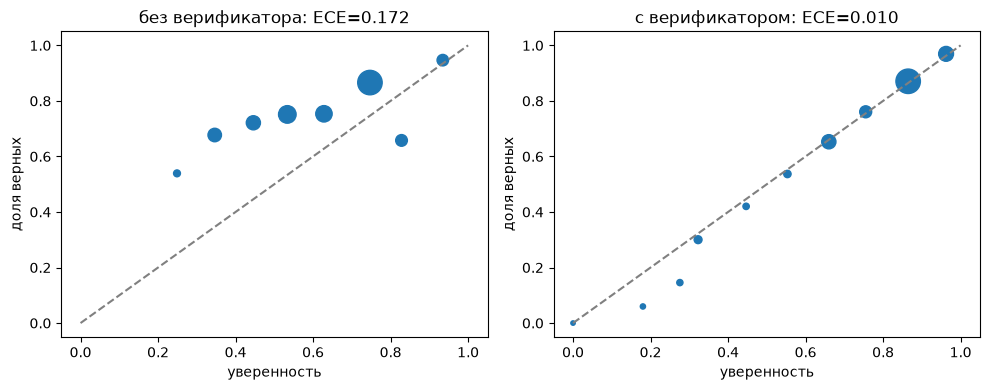

In [11]:
raw = M.score_pairs(frames["4 + шаблоны + аналоги"], gold, core, schema)
cal = M.score_pairs(frames[best], gold, core, schema)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (title, p) in zip(ax, (("без верификатора", raw), ("с верификатором", cal))):
    ece, t = M.calibration(p)
    a.plot([0, 1], [0, 1], "--", c="gray"); a.scatter(t["conf"], t["acc"], s=t["n"] / t["n"].max() * 300 + 10)
    a.set_title(f"{title}: ECE={ece:.3f}"); a.set_xlabel("уверенность"); a.set_ylabel("доля верных")
plt.tight_layout(); plt.savefig(FIG / "calibration_verifier.png"); plt.show()

## 6. Примеры: что получает модератор

In [12]:
sku = core.filter(pl.col("category_id") == "761")["sku_id"][0]
print(core.filter(pl.col("sku_id") == sku)["title"][0])
(frames[best].filter(pl.col("sku_id") == sku)
 .join(gold.select("sku_id", "attribute", pl.col("value").alias("эталон")), on=["sku_id", "attribute"], how="left")
 .select("attribute", "value", "эталон", "status", "confidence", "source", "evidence_text").sort("status", "confidence", descending=[False, True]))

Смартфон Motorola Razr 40 8/256GB Vanilla Cream


attribute,value,эталон,status,confidence,source,evidence_text
str,str,str,str,f64,str,str
"""Встроенная память (ROM)""","""256 ГБ""","""256 ГБ""","""accept""",0.99,"""lexicon+pattern""","""8/256GB"""
"""Поддержка ГЛОНАСС""","""Да""","""Да""","""accept""",0.99,"""flag""","""ГЛОНАСС"""
"""Nano-SIM""","""Да""","""Да""","""accept""",0.9748,"""flag""","""nano-SIM"""
"""Технология NFC""","""Да""","""Да""","""accept""",0.9748,"""flag""","""NFC"""
"""Оперативная память (RAM)""","""8 ГБ""","""8 ГБ""","""accept""",0.9748,"""lexicon+pattern""","""8/256GB"""
"""Поддержка GPS""","""Да""","""Да""","""accept""",0.9676,"""flag""","""GPS"""
"""Бренд""","""Motorola""","""Motorola""","""accept""",0.9676,"""brand""","""Motorola"""
"""Поддержка 5G""","""Да""","""Да""","""accept""",0.8955,"""flag""","""5G"""
"""Разъем для наушников""","""USB Type-C""","""USB Type-C""","""accept""",0.8955,"""lexicon""","""USB Type-C"""


## 7. Сохранение

In [13]:
out = {"sample": "test_core", "cards": core.height, "rows": bench.to_dicts(),
       "thresholds": {k: v[1] for k, v in verifiers.items()},
       "verifier_report": {k: v[0].report for k, v in verifiers.items()}}
(REPORTS / "benchmark_no_llm.json").write_text(json.dumps(out, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("сохранено:", REPORTS / "benchmark_no_llm.json")

сохранено: ..\reports\benchmark_no_llm.json
